<a href="https://colab.research.google.com/github/Japi20/Data201-labs/blob/main/assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Homework: Decision Trees
Jorge Pineda

## Part 1: Build a Classification Tree

In [23]:
%pip -q install ISLP

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [25]:
carseats = load_data('Carseats')

print("Missing values per column:\n", carseats.isna().sum())
print("\nTotal number of rows:", len(carseats), "\n")

display(carseats.head())


Missing values per column:
 Sales          0
CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
dtype: int64

Total number of rows: 400 



,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [26]:
# High sales = 1, low sales = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)

# Remove Sales
carseats = carseats.drop(columns=['Sales'])

print(carseats['HighSales'].value_counts())
carseats.head()

HighSales
0    236
1    164
Name: count, dtype: int64


,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,138,73,11,276,120,Bad,42,17,Yes,Yes,1
1,111,48,16,260,83,Good,65,10,Yes,Yes,1
2,113,35,10,269,80,Medium,59,12,Yes,Yes,1
3,117,100,4,466,97,Medium,55,14,Yes,Yes,0
4,141,64,3,340,128,Bad,38,13,Yes,No,0


In [27]:
X = carseats.drop(columns=['HighSales'])
y = carseats['HighSales']

X = pd.get_dummies(X, columns=['ShelveLoc', 'Urban', 'US'], dtype=int)

X.head()

,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
0,138,73,11,276,120,42,17,1,0,0,0,1,0,1
1,111,48,16,260,83,65,10,0,1,0,0,1,0,1
2,113,35,10,269,80,59,12,0,0,1,0,1,0,1
3,117,100,4,466,97,55,14,0,0,1,0,1,0,1
4,141,64,3,340,128,38,13,1,0,0,0,1,1,0


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print('Training stores:', len(X_train))
print('Test stores:', len(X_test))

Training stores: 280
Test stores: 120


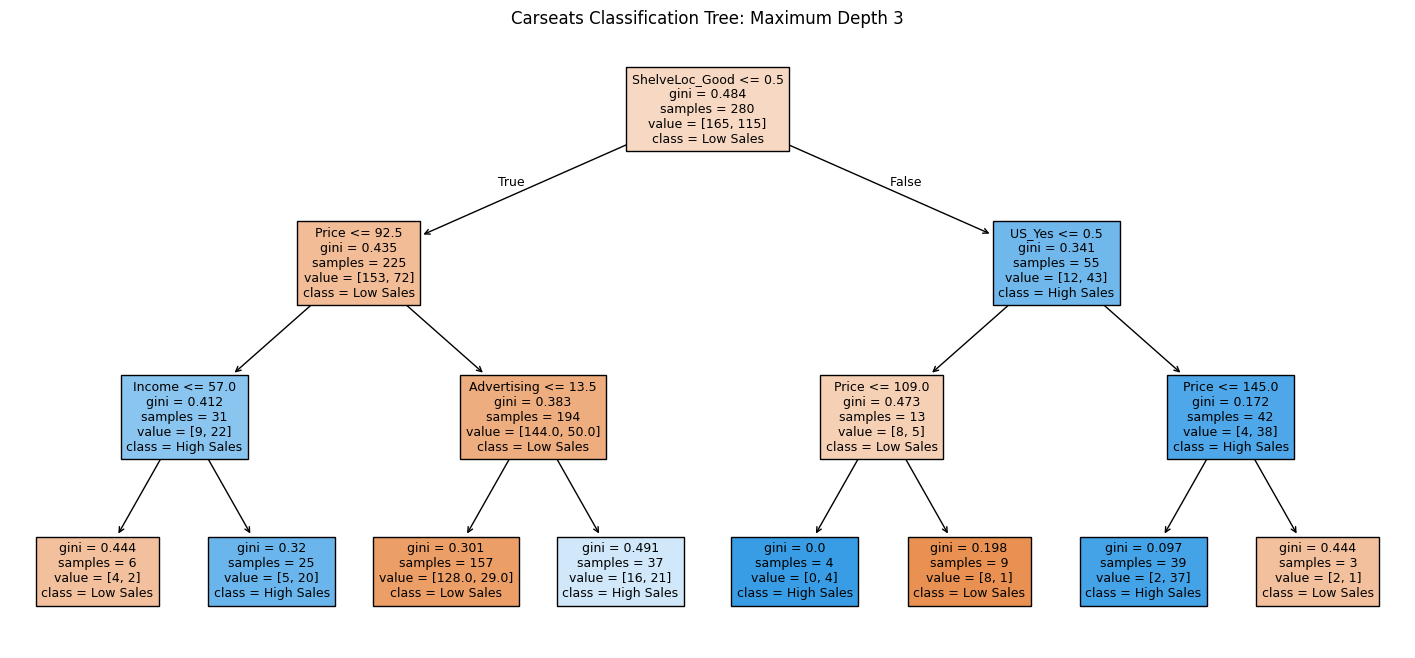

Training accuracy: 0.8
Test accuracy: 0.8


In [29]:
tree3 = DecisionTreeClassifier(max_depth=3, random_state=0)
tree3.fit(X_train, y_train)

plt.figure(figsize=(18, 8))

plot_tree(
    tree3,
    feature_names=list(X.columns),
    class_names=['Low Sales', 'High Sales'],
    filled=True,
    fontsize=9
)

plt.title('Carseats Classification Tree: Maximum Depth 3')
plt.show()

print('Training accuracy:', round(tree3.score(X_train, y_train), 3))
print('Test accuracy:', round(tree3.score(X_test, y_test), 3))

## Part 2: Investigate Overfitting

In [30]:
depths = range(1, 11)
cv_acc = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=0)

    scores = cross_val_score(
        model, X_train, y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_acc.append(scores.mean())

,Max depth,Mean CV accuracy
0,1,0.667857
1,2,0.682143
2,3,0.721429
3,4,0.746429
4,5,0.714286
5,6,0.753571
6,7,0.739286
7,8,0.739286
8,9,0.725000
9,10,0.725000


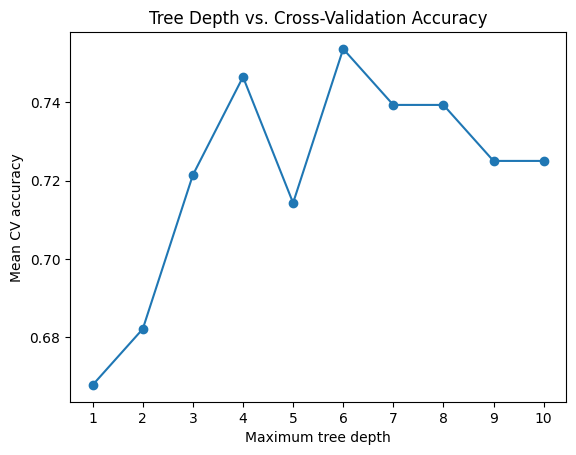

In [31]:
cv_results = pd.DataFrame({
    'Max depth': list(depths),
    'Mean CV accuracy': cv_acc
})

display(cv_results)

plt.plot(depths, cv_acc, marker='o')
plt.xticks(list(depths))
plt.xlabel('Maximum tree depth')
plt.ylabel('Mean CV accuracy')
plt.title('Tree Depth vs. Cross-Validation Accuracy')
plt.show()

In [32]:
best_depth = list(depths)[int(np.argmax(cv_acc))]

final_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=0
)
final_tree.fit(X_train, y_train)

print('Best depth:', best_depth)
print('Best mean CV accuracy:', round(max(cv_acc), 3))
print('Final test accuracy:', round(final_tree.score(X_test, y_test), 3))

Best depth: 6
Best mean CV accuracy: 0.754
Final test accuracy: 0.725


## Part 3: Written Answers

1. Interpreting the tree: Which predictor was selected for the first split (root)? What does
this split tell us about sales?

The first split uses ShelveLoc_Good, separating stores with good shelf locations from those with bad or medium shelf locations This suggests that good shelf locations are associated with higher sales.

---



2. Choosing tree depth: According to your cross-validation graph, which depth performed
best? Why should we use cross-validation rather than test accuracy to choose the depth?

Depth of 6 had the highest mean cross-validation accuracy, about 75.4%. We use cross-validation to choose the depth so the test set stays separate for evaluating the final model. Choosing the depth using test accuracy would let the test results influence our model selection.



---


3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph.

Increasing depth did not always improve cross-validation accuracy. Accuracy increased through depth 4, dropped at depth 5, and reached its highest value at depth 6. After that, it decreased or stayed the same. This suggests that adding more splits can lead to overfitting rather than better predictions on unseen observations.